# **Analisis Segmentasi Negara dan Pembangunan Ekonomi**

## **1.0 Bussines Understanding**

## **1.1 Latar Belakang**

Sebuah lembaga ingin membangun sistem untuk mengelompokkan status sosial ekonomi dan kesehatan dar berbagai negara secara otomatis.

## **1.2 Tujuan**

Membangun machine learning untuk memprediksi secara otomatis tanpa perlu melakukan penilaian secara manual

## **1.3 Masalah**

Dalam proses mengelompokkan masih menggunakan cara manual sehingga membuang waktu lama dan tidak efisien.

## **1.4 Solusi**

Solusinya yaitu dengan membangun machine learning untuk mengatasi dalam pengelompokkan ini agar dilakukan secara otomatis.

## **1.5 Deksripsi Kolom**

**1. Ukuran Data: 167 baris (mewakili 167 negara) dan 10 kolom.**


**2.  Fitur Input (X): Kolom atribut sosio-ekonomi dan kesehatan negara, yang meliputi:**
- country: Nama negara (string / teks).
- child_mort: Angka kematian anak di bawah usia 5 tahun per 1.000 kelahiran
hidup.
- exports: Persentase ekspor barang dan jasa terhadap PDB (GDP).
- health: Persentase pengeluaran total kesehatan terhadap PDB (GDP).
- imports: Persentase impor barang dan jasa terhadap PDB (GDP).
- income: Pendapatan bersih per kapita (satuan: USD)
- inflation: Tingkat pertumbuhan tahunan total inflasi dari PDB.
- life_expec: Rata-rata angka harapan hidup saat lahir (satuan: Tahun).
- total_fer: Angka kesuburan total / rata-rata jumlah anak yang dilahirkan oleh
seorang wanita.
- gdpp: Produk Domestik Bruto per kapita (satuan: USD per orang).


**3. Target Label (Y): Tidak ada label target (karena menggunakan pembelajaran tanpa**
**pengawasan / unsupervised learning), di mana algoritma bertugas menemukan**
**kelompok klaster pembangunan secara mandiri.**

## **2.0 Data Preparation**

In [124]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tkinter as tk
from tkinter import ttk

In [125]:
# df = pd.read_csv('Country-data.csv')
df = pd.read_csv('../dataset/Country-data.csv')
df.head(10)

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.440,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.490,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.100,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.440,76.8,2.13,12200
5,Argentina,14.5,18.9,8.10,16.0,18700,20.900,75.8,2.37,10300
6,Armenia,18.1,20.8,4.40,45.3,6700,7.770,73.3,1.69,3220
7,Australia,4.8,19.8,8.73,20.9,41400,1.160,82.0,1.93,51900
8,Austria,4.3,51.3,11.00,47.8,43200,0.873,80.5,1.44,46900
9,Azerbaijan,39.2,54.3,5.88,20.7,16000,13.800,69.1,1.92,5840


In [126]:
df.info()
df.describe()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


1670

Pada dataset ini memiliki 167 baris dan 10 kolom, dimana dengan tipe data numerik(float dan int) dan juga terdapat kolom string di kolom coutry. Daatset ini memiliki 1670 frame size.

In [127]:
df.isna().sum()

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

In [128]:
df.duplicated().sum()

np.int64(0)

Dataset ini tidak memiliki data yang duplicate dan data yang kosong jadi data ini termasuk bersih dan tidak ada penanganan data kosong dan data duplikat.

## **3.0 Exploratory Data Analysis**

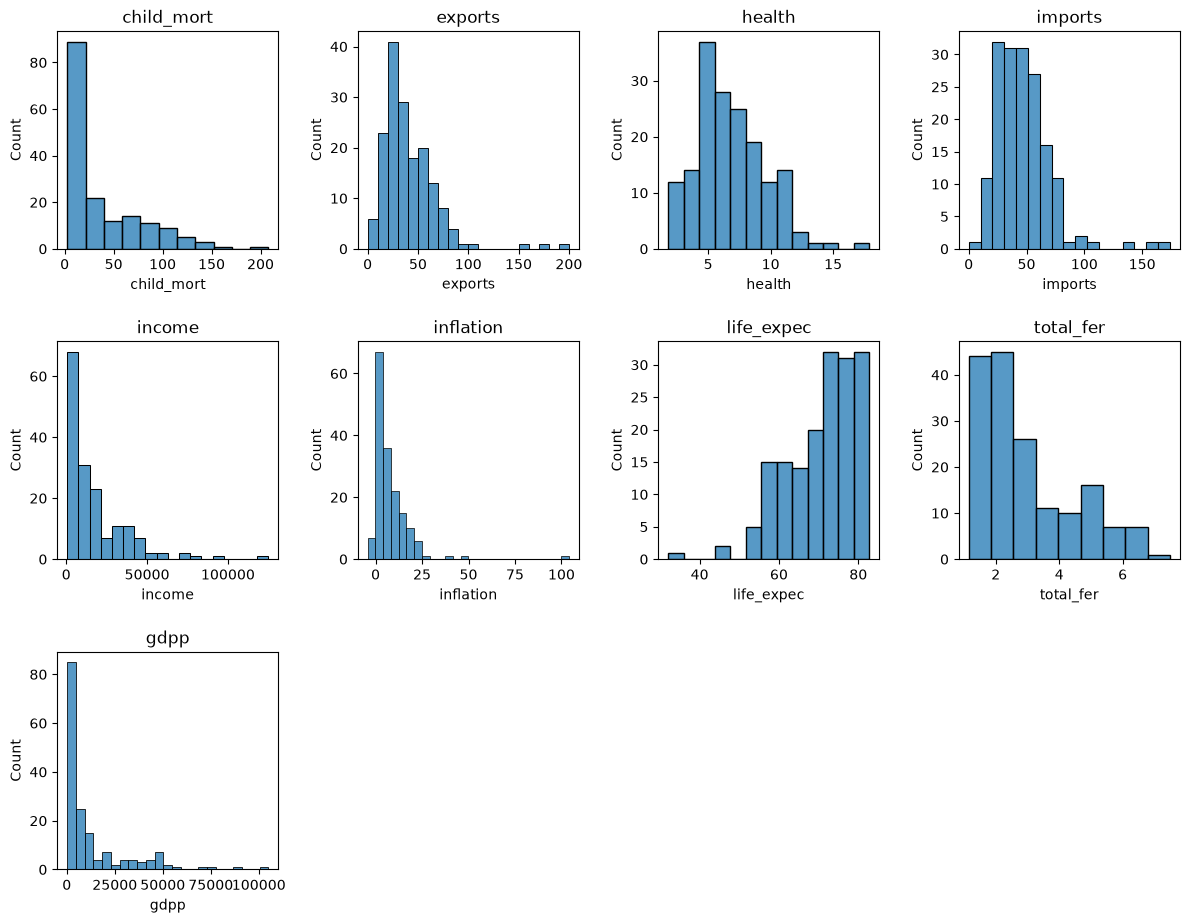

In [129]:
cols = df.select_dtypes(include=['number']).columns
 
plt.figure(figsize=(12, 12))

for i, col in enumerate(cols):
    plt.subplot(4, 4, i+1)
    sns.histplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

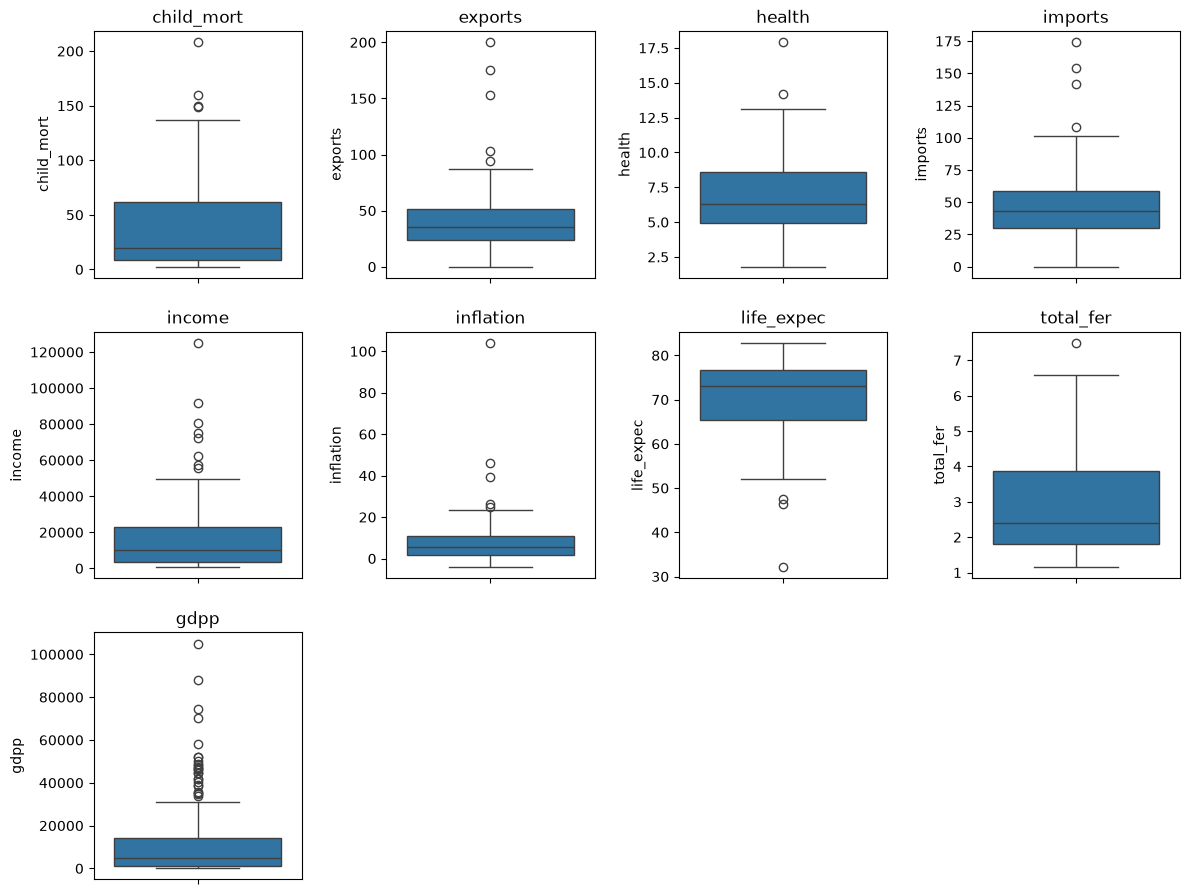

In [130]:
cols = df.select_dtypes(include=['number']).columns
 
plt.figure(figsize=(12, 12))

for i, col in enumerate(cols):
    plt.subplot(4, 4, i+1)
    sns.boxplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

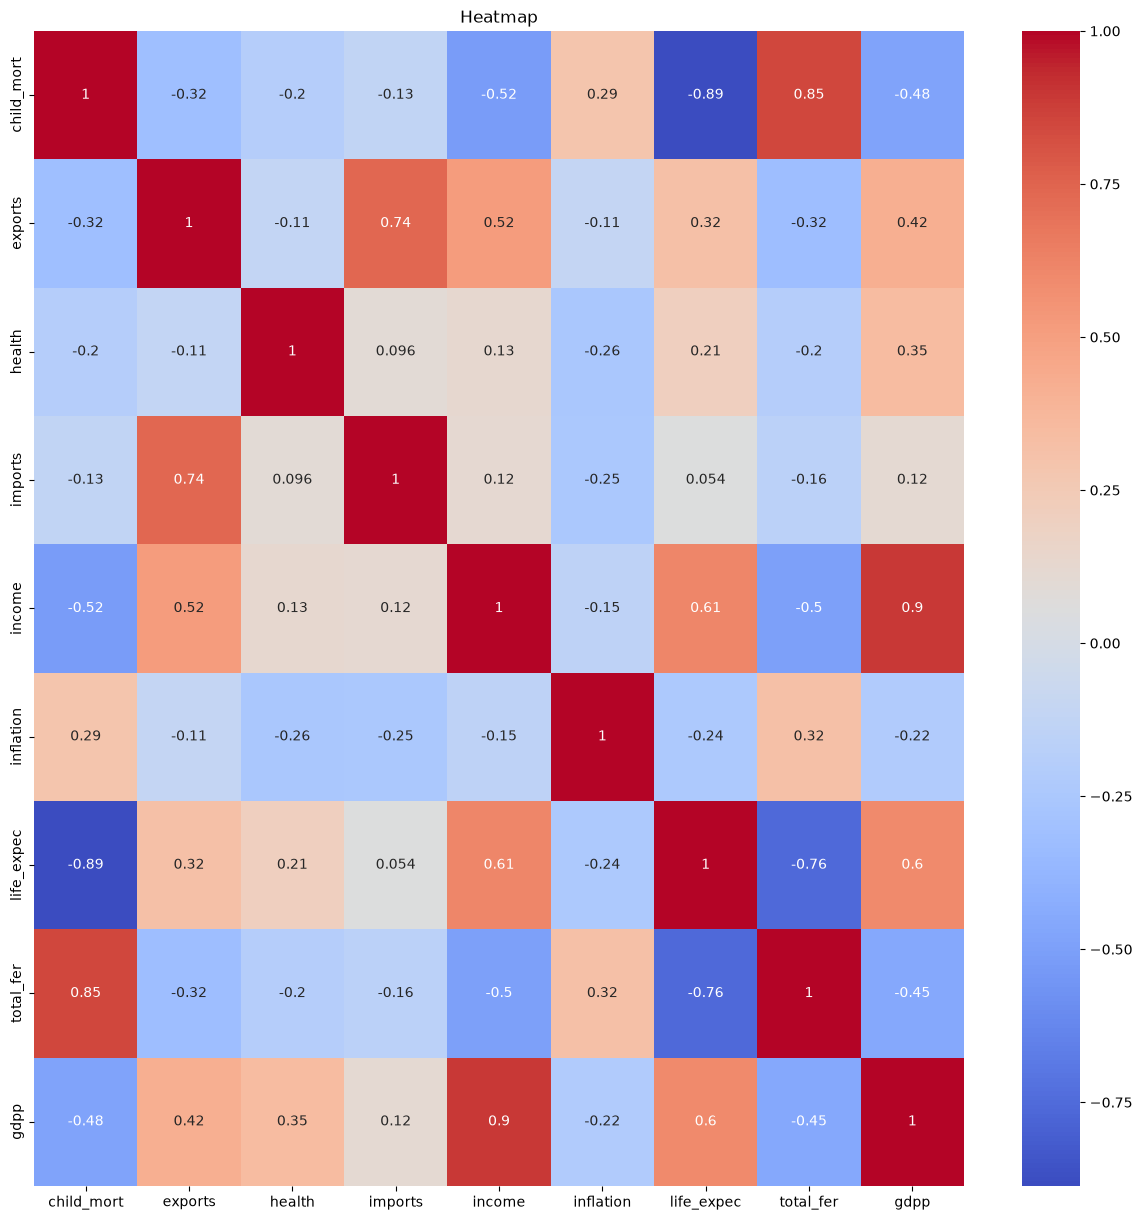

In [131]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15,15))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.title('Heatmap')
plt.show()

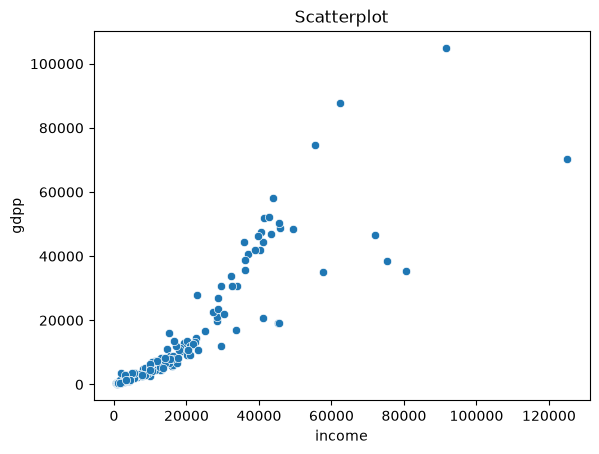

In [132]:
sns.scatterplot(x='income', y='gdpp', data=df)
plt.title('Scatterplot')
plt.show()

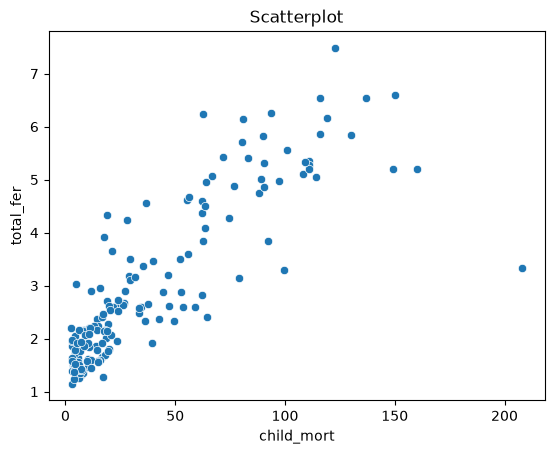

In [133]:
sns.scatterplot(x='child_mort', y='total_fer', data=df)
plt.title('Scatterplot')
plt.show()

In [134]:
cols = df.select_dtypes(include=['number']).columns

q1 = df[cols].quantile(0.25)
q3 = df[cols].quantile(0.75)

iqr = q3 - q1

bb = q1 - 1.5 * iqr
bt = q3 + 1.5 * iqr

outlier = ((df[cols] < bb) | (df[cols] > bt)).sum()
print(outlier)
print(outlier.sum())

child_mort     4
exports        5
health         2
imports        4
income         8
inflation      5
life_expec     3
total_fer      1
gdpp          25
dtype: int64
57


Pada dataset ini persebaran data yang dimiliki itu tidak normal. Kemudian terdapat outlier pada semua kolom dan tertinggi yaitu kolom gdpp dan akan dilakukan penanganan outlier cappping. 

## **4.0 Data Preprocessing**

In [135]:
df_clipped = df[cols].clip(lower=bb, upper=bt, axis=1)

outlier = ((df_clipped[cols] < bb) | (df_clipped[cols] > bt)).sum()
print(outlier)
print(outlier.sum())

child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
0


In [136]:
country = df['country']

X = df_clipped[['child_mort','inflation', 'gdpp']]

Disini saya melakukan pemisahan fitur pada kolom negara dan X karena kolom negara jika di encoding maka sangat tidak mungkin dikarenakan nantinya banyak sekali kolomnya.

In [137]:
X = df_clipped[['child_mort', 'inflation', 'gdpp']]

mean = np.mean(X, axis=0)
std = np.std(X, axis=0)

X_scaled = (X - mean) / std

X_scaled[:5]

,child_mort,inflation,gdpp
0,1.369802,0.355270,-0.846341
1,-0.550464,-0.385208,-0.540827
2,-0.271295,1.351551,-0.508868
3,2.121210,2.293979,-0.589198
4,-0.714835,-0.841463,0.159686


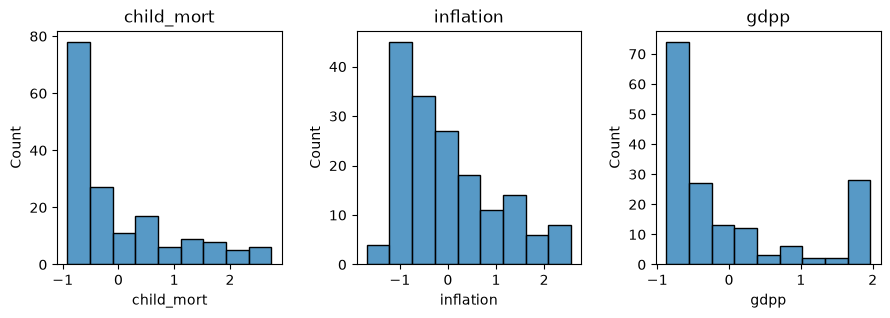

In [138]:
cols = X_scaled.select_dtypes(include=['number']).columns
 
plt.figure(figsize=(12, 12))

for i, col in enumerate(cols):
    plt.subplot(4, 4, i+1)
    sns.histplot(X_scaled[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

Dan disini terdapat standarisasi data supaya dalam perhitungan jarak dengan skala yang seimbang

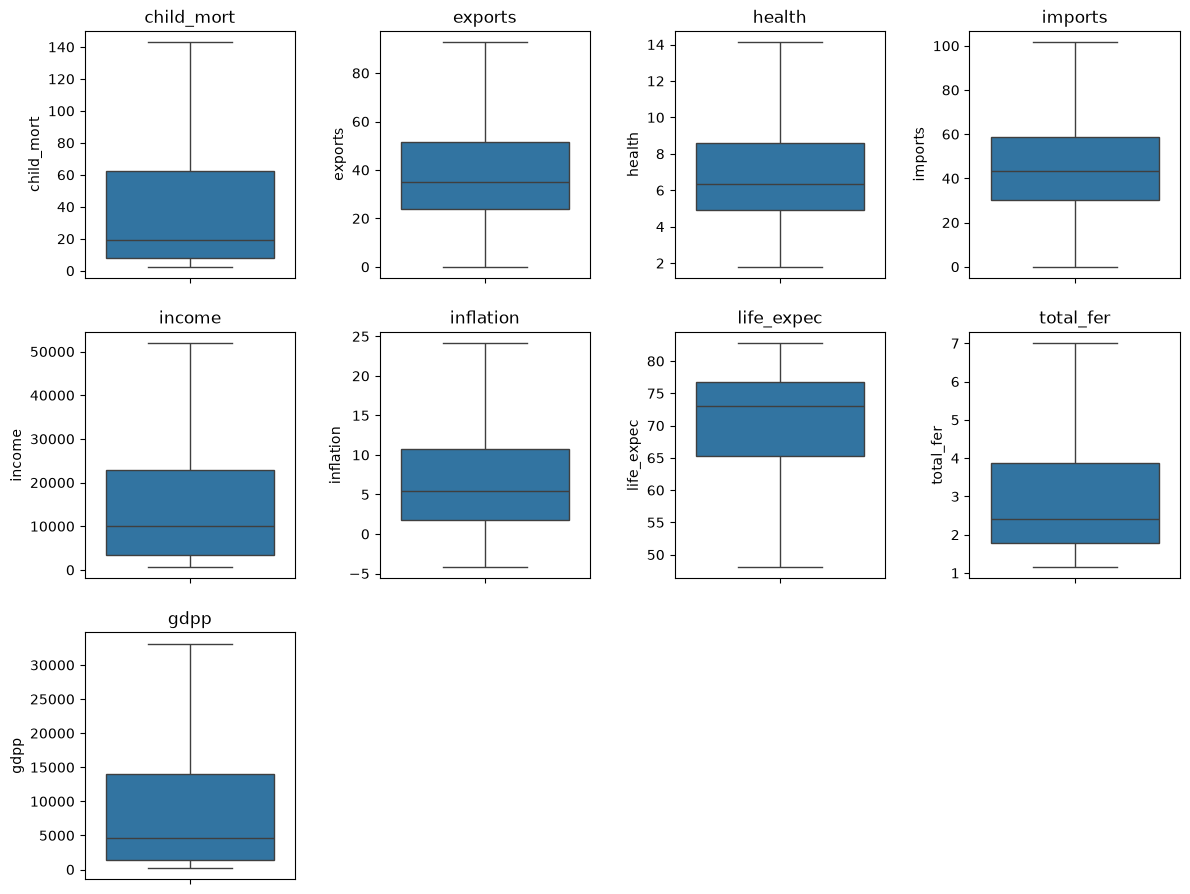

In [139]:
cols = df_clipped.select_dtypes(include=['number']).columns
 
plt.figure(figsize=(12, 12))

for i, col in enumerate(cols):
    plt.subplot(4, 4, i+1)
    sns.boxplot(df_clipped[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

In [140]:
X_scaled = X_scaled.to_numpy()

print("Mean setelah scaling:")
print(np.mean(X_scaled, axis=0))

print("Standar deviasi setelah scaling:")
print(np.std(X_scaled, axis=0))


Mean setelah scaling:
[-2.12737346e-17 -3.19106019e-17  2.12737346e-17]
Standar deviasi setelah scaling:
[1. 1. 1.]


## **5.0 Modeling**

In [141]:
class Kmeanspp:
    def __init__(self, k=3, max_iter=100, random_state=None):
        self.k = k
        self.max_iter = max_iter
        self.random_state = random_state
        
    def euclidean(self,X):
        return np.sqrt(((X - self.centroid[:, np.newaxis]) **2).sum(axis=2))
    
    def fit(self,X):
        X = np.asarray(X)
        np.random.seed(self.random_state)
        
        centroids = [X[np.random.choice(len(X))]]
        for _ in range(1, self.k):
            jarak_sq = np.min([np.sum((X - c)**2, axis=1)for c in centroids], axis=0)
            prob = jarak_sq / jarak_sq.sum()
            centroids.append(X[np.random.choice(len(X), p= prob)])
        self.centroid = np.array(centroids)
        
        for _ in range(self.max_iter):
            self.labels = np.argmin(self.euclidean(X), axis=0)
            centorid_baru = np.array([
                X[self.labels == i].mean(axis=0)
                if np.any(self.labels == i)
                else X[np.random.choice(len(X))]
                for i in range(self.k)
            ])
            
            if np.allclose(self.centroid, centorid_baru):
                break
            self.centroid = centorid_baru
            
        self.sse = np.sum((X - self.centroid[self.labels])**2)
        return self
    
    def predict(self,X):
        X = np.asarray(X)
        return np.argmin(self.euclidean(X), axis=0)

In [142]:
model = Kmeanspp(k = 3, random_state=89)
model.fit(X_scaled)
print('sse', model.sse)
print('label', model.labels)

sse 191.05937790294917
label [1 0 0 1 0 0 0 2 2 0 2 2 0 2 0 2 0 1 0 0 0 0 0 2 0 1 1 0 1 2 0 1 1 0 0 0 1
 1 1 0 1 0 2 2 2 0 0 0 0 1 0 0 0 2 2 1 1 0 2 1 2 0 0 1 1 0 1 0 2 0 0 0 0 2
 2 2 0 2 0 0 0 0 2 0 1 0 0 1 1 0 0 2 0 1 1 0 0 1 2 1 0 0 0 0 0 0 1 0 0 0 2
 2 1 1 2 0 1 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 1 2 2 2 0 0 2 2 0 0 1 0 2 2 0 1
 0 1 1 0 0 0 0 1 0 2 2 2 0 0 0 0 0 1 1]


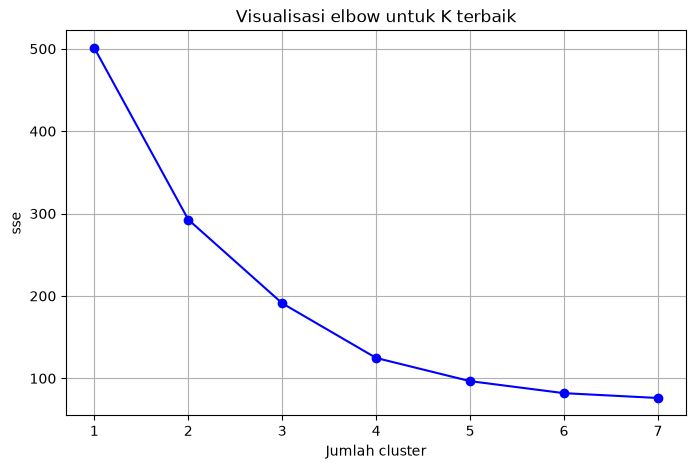

In [143]:
sse_list=[]
ks = range(1,8)
for k in ks:
    model_k = Kmeanspp(k=k,random_state=89)
    model_k.fit(X_scaled)
    
    sse_list.append(model_k.sse)

plt.figure(figsize=(8,5))
plt.plot(ks,sse_list, 'bo-')
plt.grid(True)
plt.title("Visualisasi elbow untuk K terbaik")
plt.xlabel('Jumlah cluster')
plt.ylabel("sse")
plt.show()

K = 2 -> Silhouette Score: 0.3584
K = 3 -> Silhouette Score: 0.4196
K = 4 -> Silhouette Score: 0.4588
K = 5 -> Silhouette Score: 0.4637
K = 6 -> Silhouette Score: 0.4351
K = 7 -> Silhouette Score: 0.4052

Jumlah cluster terbaik berdasarkan Silhouette Score: K = 5


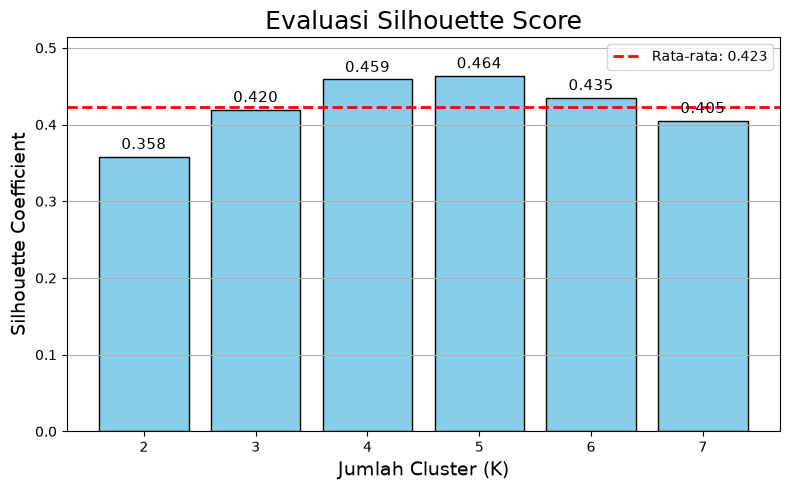

In [144]:
def silhouette_score(X, labels):
  clusters = np.unique(labels)
  if len(clusters) < 2:
    return 0.0

  dist = np.linalg.norm(X[:, None] - X[None, :], axis=2)
  scores = []

  for i, c_i in enumerate(labels):
    same = labels == c_i
    if np.sum(same) <= 1:
      scores.append(0.0)
      continue

    a = np.sum(dist[i, same]) / (np.sum(same) - 1)
    b = min(np.mean(dist[i, labels == c]) for c in clusters if c != c_i)
    scores.append((b - a) / max(a, b))

  return np.mean(scores)

ks_eval = range(2, 8)  
silhouette_scores = []

for k in ks_eval:
    model_k = Kmeanspp(k=k, random_state=89)
    model_k.fit(X_scaled)
    score = silhouette_score(X_scaled, model_k.labels)
    silhouette_scores.append(score)
    print(f'K = {k} -> Silhouette Score: {score:.4f}')

best_k = list(ks_eval)[np.argmax(silhouette_scores)]
print(f'\nJumlah cluster terbaik berdasarkan Silhouette Score: K = {best_k}')


plt.figure(figsize=(8, 5))
bars = plt.bar(list(ks_eval), silhouette_scores, color='#87CEEB', edgecolor='black')

avg_score = np.mean(silhouette_scores)
plt.axhline(y=avg_score, color='red', linestyle='--', linewidth=2,
            label=f'Rata-rata: {avg_score:.3f}')

for bar, score in zip(bars, silhouette_scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
             f'{score:.3f}', ha='center', va='bottom', fontsize=11)

plt.title('Evaluasi Silhouette Score', fontsize=18)
plt.xlabel('Jumlah Cluster (K)', fontsize=14)
plt.ylabel('Silhouette Coefficient', fontsize=14)
plt.xticks(list(ks_eval))
plt.ylim(0, np.max(silhouette_scores) + 0.05)
plt.grid(True, axis='y')
plt.legend()
plt.tight_layout(w_pad=4, h_pad=2)
plt.show()


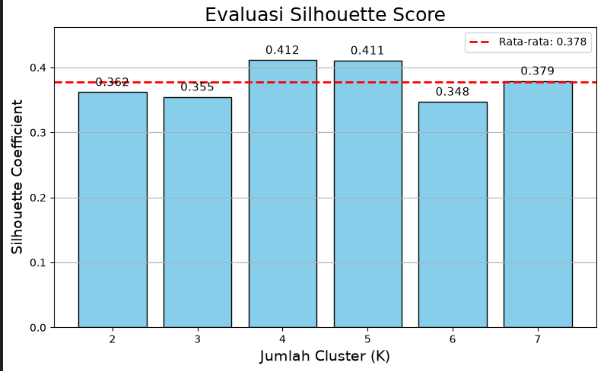

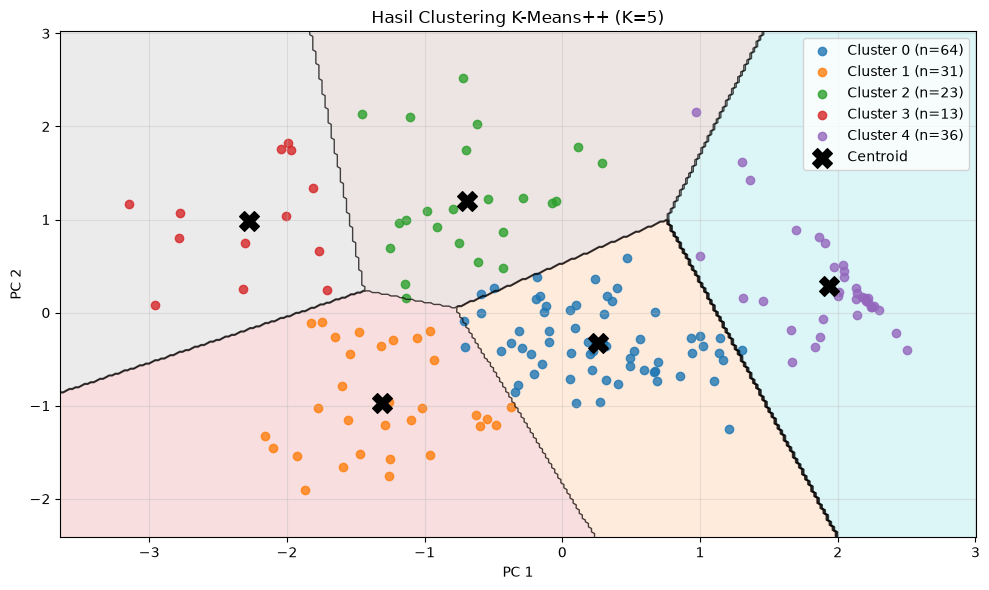

In [145]:
# ==================================
# 1. MODELING K-MEANS++
# ==================================

model = Kmeanspp(k=best_k, random_state=89)
model.fit(X_scaled)

labels = model.labels

# ==================================
# 2. PCA MENJADI 2 DIMENSI
# ==================================

X_mean = X_scaled.mean(axis=0)
X_cen = X_scaled - X_mean

vals, vecs = np.linalg.eigh(
    np.cov(X_cen, rowvar=False)
)

W = vecs[:, np.argsort(vals)[::-1][:2]]

# Transformasi data ke PCA
X_pca = X_cen @ W

# Transformasi centroid ke PCA
cent_pca = (model.centroid - X_mean) @ W


# ==================================
# 3. MEMBUAT GRID PCA
# ==================================

x_min = X_pca[:, 0].min() - 0.5
x_max = X_pca[:, 0].max() + 0.5

y_min = X_pca[:, 1].min() - 0.5
y_max = X_pca[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Menggabungkan koordinat grid
grid_pca = np.c_[xx.ravel(), yy.ravel()]


# ==================================
# 4. MENGEMBALIKAN GRID KE RUANG FITUR
# ==================================

grid_scaled = grid_pca @ W.T + X_mean


# ==================================
# 5. MENGHITUNG JARAK KE CENTROID
# ==================================

distances = np.linalg.norm(
    grid_scaled[:, np.newaxis] - model.centroid,
    axis=2
)

# Menentukan centroid terdekat
Z = np.argmin(distances, axis=1)

Z = Z.reshape(xx.shape)


# ==================================
# 6. VISUALISASI AREA DAN BATAS
# ==================================

plt.figure(figsize=(10, 6))

cmap = plt.get_cmap("tab10")

# Area warna berdasarkan centroid terdekat
plt.contourf(
    xx,
    yy,
    Z,
    levels=np.arange(best_k + 1) - 0.5,
    cmap=cmap,
    alpha=0.15
)

# Garis batas antarcluster
plt.contour(
    xx,
    yy,
    Z,
    levels=np.arange(best_k - 1) + 0.5,
    colors="black",
    linewidths=1,
    alpha=0.7
)


# ==================================
# 7. MENAMPILKAN TITIK DATA
# ==================================

for c in range(best_k):

    m = labels == c

    plt.scatter(
        X_pca[m, 0],
        X_pca[m, 1],
        color=cmap(c),
        alpha=0.8,
        label=f"Cluster {c} (n={m.sum()})"
    )


# ==================================
# 8. MENAMPILKAN CENTROID
# ==================================

plt.scatter(
    cent_pca[:, 0],
    cent_pca[:, 1],
    c="black",
    marker="X",
    s=200,
    label="Centroid",
    zorder=5
)


# ==================================
# 9. PENGATURAN GRAFIK
# ==================================

plt.title(f"Hasil Clustering K-Means++ (K={best_k})")

plt.xlabel("PC 1")
plt.ylabel("PC 2")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## **7.0 GUI**

In [147]:
# =====================================================================
# 7.0 GUI - Prediksi Klaster Negara (K-Means++)
# ---------------------------------------------------------------------
# GUI ini punya 2 fungsi:
#   1. Prediksi Manual  : pilih Nama Negara (combo) + isi 3 indikator
#                         -> tekan "Prediksi" -> muncul cluster-nya.
#   2. Hasil Clustering : tombol "Daftar Negara" menampilkan tabel
#                         seluruh negara + cluster-nya.
#
# Catatan: nama negara HANYA sebagai label/penamaan hasil prediksi.
# Model tetap memakai 3 fitur numerik: child_mort, inflation, gdpp.
#
# Prasyarat: jalankan cell-cell di atas dulu, karena GUI ini memakai:
#   df_clipped, country, X_scaled, mean, std, model, labels, best_k
#
# Cara pakai:
#   1. Jalankan cell ini -> muncul jendela.
#   2. Pilih negara, isi nilai fitur, lalu klik "Prediksi".
#   3. Klik "Daftar Negara" untuk melihat cluster semua negara.
#   4. Tutup jendela untuk menghentikan cell.
# =====================================================================

import numpy as np
import pandas as pd
import tkinter as tk
from tkinter import ttk


# ============================================================
# 1. KONFIGURASI FITUR
# ============================================================
# label   : tulisan yang muncul di form
# default : nilai awal yang sudah terisi
# PENTING: urutan fitur harus SAMA dengan urutan saat model dilatih.
KONFIGURASI = {
    "child_mort": {
        "label": "Kematian Anak (per 1000)",
        "type": "number",
        "default": 30.0
    },
    "inflation": {
        "label": "Inflasi (%)",
        "type": "number",
        "default": 5.0
    },
    "gdpp": {
        "label": "PDB per Kapita (USD)",
        "type": "number",
        "default": 5000.0
    }
}

FITUR = list(KONFIGURASI.keys())


# ============================================================
# 2. VALIDASI DATA TRAINING
# ============================================================
for _nama in ["df_clipped", "country", "X_scaled", "mean", "std", "model", "labels"]:
    if _nama not in dir():
        raise NameError(
            "Variabel '{}' belum ada. Jalankan cell-cell di atas "
            "sampai proses modeling selesai, barulah jalankan cell GUI ini.".format(_nama)
        )

labels_arr = np.asarray(labels)

# Nama negara asli (urutannya sama dengan df_clipped)
NEGARA_ASLI = np.asarray(country)

# Daftar nama negara untuk combo (tanpa duplikat, urut abjad)
NEGARA_LIST = sorted(set(NEGARA_ASLI.tolist()))

# Menggabungkan nama negara dengan hasil clustering
df_hasil = pd.DataFrame({
    "country": NEGARA_ASLI,
    "cluster": labels_arr
}).sort_values("country").reset_index(drop=True)

if len(df_clipped) != len(labels_arr):
    raise ValueError("Jumlah df_clipped tidak sama dengan jumlah labels.")

if not all(kolom in df_clipped.columns for kolom in FITUR):
    raise ValueError("Ada fitur yang tidak ditemukan dalam df_clipped.")


# ============================================================
# 3. PROFIL CLUSTER
# ============================================================
def buat_profil_cluster():
    """Rata-rata tiap fitur untuk masing-masing cluster."""
    hasil = {}
    for cluster in range(len(np.unique(labels_arr))):
        data = df_clipped.loc[labels_arr == cluster, FITUR]
        if data.empty:
            raise ValueError("Cluster {} tidak memiliki data.".format(cluster))
        hasil[cluster] = {
            kolom: float(data[kolom].mean())
            for kolom in FITUR
        }
    return hasil


PROFILES = buat_profil_cluster()


# ============================================================
# 4. PARAMETER NORMALISASI (z-score: (x - mean) / std)
# ============================================================
MEAN_V = np.asarray(mean, dtype=float).reshape(-1)
STD_V = np.asarray(std, dtype=float).reshape(-1)

if len(MEAN_V) != len(FITUR):
    raise ValueError(
        "Jumlah MEAN_V ({}) tidak sesuai dengan jumlah fitur ({}). "
        "Pastikan cell training memakai fitur yang sama dengan KONFIGURASI.".format(
            len(MEAN_V), len(FITUR))
    )

if len(STD_V) != len(FITUR):
    raise ValueError(
        "Jumlah STD_V ({}) tidak sesuai dengan jumlah fitur ({}).".format(
            len(STD_V), len(FITUR))
    )

if not np.all(np.isfinite(MEAN_V)):
    raise ValueError("MEAN_V mengandung nilai tidak valid.")

if not np.all(np.isfinite(STD_V)):
    raise ValueError("STD_V mengandung nilai tidak valid.")

# Mencegah pembagian dengan nol
STD_AMAN = np.where(STD_V == 0, 1, STD_V)


# ============================================================
# 5. LOGIKA PREDIKSI
# ============================================================
def normalisasi_data(data):
    """Ubah input dari satuan asli menjadi skala standar (z-score)."""
    x = np.array([[data[kolom] for kolom in FITUR]], dtype=float)
    return (x - MEAN_V) / STD_AMAN


def prediksi_cluster(data):
    """Tentukan cluster dari data input."""
    x_skala = normalisasi_data(data)
    cluster = int(model.predict(x_skala)[0])
    if cluster not in PROFILES:
        raise ValueError("Cluster {} tidak ditemukan.".format(cluster))
    return cluster


# ============================================================
# 6. FORMAT HASIL
# ============================================================
def format_profil(data, cluster):
    """Bandingkan input pengguna dengan rata-rata cluster."""
    profil = PROFILES[cluster]
    hasil = []

    for kolom, config in KONFIGURASI.items():
        label = config["label"]
        input_nilai = "{:.2f}".format(data[kolom])
        rata_rata = "{:.2f}".format(profil[kolom])
        hasil.append(
            "{:<30} {:>14} {:>20}".format(label, input_nilai, rata_rata)
        )

    header = "{:<30} {:>14} {:>20}".format(
        "Fitur", "Input Anda", "Rata-rata Cluster")

    return "\n".join([header, "-" * 66] + hasil)


# ============================================================
# 7. APLIKASI GUI
# ============================================================
class Aplikasi(tk.Tk):

    def __init__(self):
        super().__init__()
        self.title("Prediksi Klaster Negara - K-Means++")
        self.geometry("720x620")
        self.resizable(False, False)

        self.entries = {}
        self._build_form()
        self._pesan("Pilih negara dan isi indikatornya, lalu tekan 'Prediksi'.")

    # --------------------------------------------------------
    def _build_form(self):
        # Header
        header = tk.Frame(self, bg="#1f4e79", height=75)
        header.pack(fill="x")

        tk.Label(header, text="Prediksi Klaster Negara",
                 bg="#1f4e79", fg="white",
                 font=("Segoe UI", 15, "bold")).pack(pady=(12, 0))
        tk.Label(header, text="K-Means++ Clustering",
                 bg="#1f4e79", fg="white",
                 font=("Segoe UI", 10)).pack(pady=(0, 12))

        # Panel hasil (di bawah)
        self._build_result()

        # Area form
        container = ttk.Frame(self)
        container.pack(fill="both", expand=True, padx=20, pady=15)

        self.form = ttk.Frame(container, padding=10)
        self.form.pack(fill="both", expand=True)
        self.form.columnconfigure(1, weight=1)

        self._build_inputs()
        self._build_buttons()

    # --------------------------------------------------------
    def _build_result(self):
        self.cluster_var = tk.StringVar(value="Hasil prediksi")

        self.result_frame = tk.Frame(self, bg="#eaf2f8", padx=14, pady=12)
        self.result_frame.pack(side="bottom", fill="x", padx=20, pady=(0, 15))

        self.cluster_label = tk.Label(
            self.result_frame, textvariable=self.cluster_var,
            font=("Segoe UI", 16, "bold"),
            bg="#eaf2f8", fg="#1f4e79", anchor="w", wraplength=640)
        self.cluster_label.pack(fill="x", pady=(0, 8))

        self.result_text = tk.Text(
            self.result_frame, height=7, wrap="none",
            font=("Consolas", 9), bg="#eaf2f8", fg="#333333",
            relief="flat", state="disabled")
        self.result_text.pack(fill="both", expand=True)

    # --------------------------------------------------------
    def _build_inputs(self):
        # Baris 0: Nama Negara (hanya label/penamaan hasil)
        ttk.Label(self.form, text="Nama Negara",
                  font=("Segoe UI", 10, "bold")).grid(
            row=0, column=0, sticky="w", padx=(0, 12), pady=8)

        self.country_var = tk.StringVar(value=NEGARA_LIST[0])
        self.country_combo = ttk.Combobox(
            self.form, textvariable=self.country_var,
            values=NEGARA_LIST, state="readonly", font=("Segoe UI", 10))
        self.country_combo.grid(row=0, column=1, sticky="ew", pady=8)

        # Baris 1..n: fitur numerik
        for r, (kolom, config) in enumerate(KONFIGURASI.items(), start=1):
            ttk.Label(self.form, text=config["label"],
                      font=("Segoe UI", 10)).grid(
                row=r, column=0, sticky="w", padx=(0, 12), pady=8)

            widget = ttk.Entry(self.form, font=("Segoe UI", 10))
            widget.insert(0, str(config["default"]))
            widget.grid(row=r, column=1, sticky="ew", pady=8)
            self.entries[kolom] = widget

    # --------------------------------------------------------
    def _build_buttons(self):
        tombol = ttk.Frame(self.form)
        tombol.grid(row=len(KONFIGURASI) + 1, column=0, columnspan=2,
                    sticky="ew", pady=20)

        daftar_tombol = [
            ("Isi Otomatis", self.on_autofill),
            ("Prediksi", self.on_predict),
            ("Reset", self.on_reset),
            ("Daftar Negara", self.on_daftar_negara),
        ]

        for kolom in range(len(daftar_tombol)):
            tombol.columnconfigure(kolom, weight=1)

        for kolom, (label, aksi) in enumerate(daftar_tombol):
            ttk.Button(tombol, text=label, command=aksi).grid(
                row=0, column=kolom, sticky="ew", padx=5, ipady=6)

    # --------------------------------------------------------
    def _pesan(self, teks, bg="#f2f2f2", fg="#333333"):
        self.result_text.configure(state="normal")
        self.result_text.delete("1.0", tk.END)
        self.result_text.insert("1.0", teks)
        self.result_text.configure(state="disabled", bg=bg, fg=fg)
        self.cluster_label.configure(bg=bg, fg=fg)
        self.result_frame.configure(bg=bg)

    # --------------------------------------------------------
    def _kumpulkan_input(self):
        data = {}
        for kolom, entry in self.entries.items():
            teks = entry.get().strip().replace(",", ".")
            if not teks:
                raise ValueError(
                    "{} tidak boleh kosong.".format(KONFIGURASI[kolom]["label"]))
            try:
                nilai = float(teks)
            except ValueError:
                raise ValueError(
                    "{} harus berupa angka.".format(KONFIGURASI[kolom]["label"]))
            if not np.isfinite(nilai):
                raise ValueError(
                    "{} tidak valid.".format(KONFIGURASI[kolom]["label"]))
            data[kolom] = nilai
        return data

    # --------------------------------------------------------
    def on_predict(self):
        try:
            negara = self.country_var.get().strip()
            if not negara:
                raise ValueError("Nama Negara belum dipilih.")

            data = self._kumpulkan_input()
            cluster = prediksi_cluster(data)
            teks = format_profil(data, cluster)

            self.cluster_var.set(
                "{} - TERMASUK CLUSTER {}".format(negara.upper(), cluster))
            self._pesan(teks, "#d9ead3", "#1e6b34")
        except ValueError as err:
            self.cluster_var.set("Periksa input")
            self._pesan("Input tidak valid: {}".format(err), "#f8d7da", "#a12622")

    # --------------------------------------------------------
    def on_autofill(self):
        pos = int(np.random.randint(len(df_clipped)))
        baris = df_clipped.iloc[pos]

        for kolom, entry in self.entries.items():
            entry.delete(0, tk.END)
            entry.insert(0, "{:.6g}".format(float(baris[kolom])))

        self.country_var.set(str(NEGARA_ASLI[pos]))

        self.cluster_var.set("Data contoh siap")
        self._pesan("Data contoh berhasil diisi. Tekan Prediksi untuk melihat hasil.")

    # --------------------------------------------------------
    def on_reset(self):
        for kolom, entry in self.entries.items():
            entry.delete(0, tk.END)
            entry.insert(0, str(KONFIGURASI[kolom]["default"]))

        self.country_var.set(NEGARA_LIST[0])

        self.cluster_var.set("Hasil prediksi")
        self._pesan("Form berhasil direset. Silakan masukkan data.")

    # --------------------------------------------------------
    def on_daftar_negara(self):
        """Membuka jendela berisi tabel semua negara + cluster-nya."""
        jendela = tk.Toplevel(self)
        jendela.title("Hasil Clustering Negara")
        jendela.geometry("620x520")

        ttk.Label(jendela, text="Cari nama negara:").pack(
            anchor="w", padx=15, pady=(12, 0))

        cari_var = tk.StringVar()
        ttk.Entry(jendela, textvariable=cari_var).pack(
            fill="x", padx=15, pady=(2, 8))

        wadah = ttk.Frame(jendela)
        wadah.pack(fill="both", expand=True, padx=15, pady=(0, 15))

        tabel = ttk.Treeview(wadah, columns=("country", "cluster"), show="headings")
        tabel.heading("country", text="Nama Negara")
        tabel.heading("cluster", text="Kategori Cluster")
        tabel.column("country", width=360)
        tabel.column("cluster", width=180, anchor="center")

        vsb = ttk.Scrollbar(wadah, orient="vertical", command=tabel.yview)
        tabel.configure(yscrollcommand=vsb.set)
        tabel.grid(row=0, column=0, sticky="nsew")
        vsb.grid(row=0, column=1, sticky="ns")
        wadah.columnconfigure(0, weight=1)
        wadah.rowconfigure(0, weight=1)

        def isi_tabel(*_):
            kata = cari_var.get().strip().lower()
            tabel.delete(*tabel.get_children())
            for _, row in df_hasil.iterrows():
                if kata and kata not in str(row["country"]).lower():
                    continue
                tabel.insert("", "end", values=(
                    row["country"], "Cluster {}".format(int(row["cluster"]))))

        cari_var.trace_add("write", isi_tabel)
        isi_tabel()


# ============================================================
# 8. MENJALANKAN APLIKASI
# ============================================================
app = Aplikasi()
app.mainloop()
